# CUB-200-2011 — Exploratory Data Analysis (EDA) & Preprocessing

**Project:** From Pixels to Language — CSE 485 / CSE 488  
**Dataset:** CUB-200-2011 with human-written bird descriptions

This notebook runs the existing preprocessing pipeline and then explores the processed dataset. The original source data and the project's Python modules are not modified.

### EDA objectives
1. Inspect the number of images in each of the 200 bird classes and identify possible class imbalance.
2. Examine image dimensions to understand whether resizing is necessary.
3. Analyze caption lengths in words to support the image-captioning task.
4. Identify the most frequent descriptive words used in the captions.

> **Important:** The plots and statistics are calculated from the generated processed metadata. Open the notebook from the project folder or its `notebooks` subfolder. The setup cell detects the project root automatically. On the first run, preprocessing may take some time because it scans and exports the dataset.


## 1. Project setup

The notebook automatically searches the current Jupyter folder and its parent folders for the project root. It expects the existing module at `src/data/preprocessing.py`.

No changes are made to `preprocessing.py` or `transforms.py`.


In [1]:
from pathlib import Path
import sys

# Find the project root whether Jupyter was opened from the project folder
# itself or from a subfolder such as "notebooks".
current_dir = Path.cwd()
ROOT = None

for candidate in (current_dir, *current_dir.parents):
    preprocessing_file = candidate / "src" / "data" / "preprocessing.py"
    if preprocessing_file.is_file():
        ROOT = candidate
        break

if ROOT is None:
    expected = current_dir / "src" / "data" / "preprocessing.py"
    raise FileNotFoundError(
        "Could not locate the project root. I searched the current folder "
        "and its parent folders for:\n"
        "src/data/preprocessing.py\n\n"
        "Make sure the original preprocessing.py file is inside your project "
        "at src/data/preprocessing.py, then reopen the notebook from the "
        "project folder or its notebooks subfolder.\n"
        f"Current Jupyter folder: {current_dir}"
    )

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

print(f"Project root detected: {ROOT}")
print(f"Preprocessing module: {ROOT / 'src' / 'data' / 'preprocessing.py'}")


Project root detected: c:\Users\Hager\OneDrive - Faculty of Engineering Ain Shams University\Material_7\Deep Learnning\-DeepLearnig
Preprocessing module: c:\Users\Hager\OneDrive - Faculty of Engineering Ain Shams University\Material_7\Deep Learnning\-DeepLearnig\src\data\preprocessing.py


## 2. Run the existing preprocessing pipeline

This step loads the official train and test splits, scans the images and captions, excludes unreadable images, missing labels and exact pixel duplicates, then exports the processed metadata and images.

The pipeline also creates the EDA summary files under `outputs/eda/`.


In [2]:
from src.data.preprocessing import main

# Run the existing preprocessing pipeline without modifying its source code.
main()


c:\Users\Hager\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
INFO: Loading official Hugging Face splits; local cache (C:/hf_cache) will be reused.
INFO: HTTP Request: GET https://huggingface.co/api/agent-harnesses "HTTP/1.1 200 OK"
INFO: HTTP Request: HEAD https://huggingface.co/datasets/Multimodal-Fatima/CUB_train/resolve/main/README.md "HTTP/1.1 307 Temporary Redirect"
INFO: HTTP Request: HEAD https://huggingface.co/api/resolve-cache/datasets/Multimodal-Fatima/CUB_train/bd3988995e6db193427255abdebd522afe24ce76/README.md?%2Fdatasets%2FMultimodal-Fatima%2FCUB_train%2Fresolve%2Fmain%2FREADME.md=&etag=%22e34e63275d481e3a7de165f29b772c08fbaa097f%22 "HTTP/1.1 200 OK"
INFO: HTTP Request: HEAD https://huggingface.co/datasets/Multimodal-Fatima/CUB_train/resolve/bd3988995e6db19342

## 3. Load processed metadata

We combine the train, validation and test metadata for dataset-level EDA. The original split column is kept so the data can still be inspected by split when needed.


In [3]:
import json
import re
from collections import Counter

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

SPLITS = ("train", "validation", "test")
metadata_frames = []

for split in SPLITS:
    csv_path = ROOT / "data" / "processed" / "metadata" / f"{split}.csv"
    if not csv_path.exists():
        raise FileNotFoundError(
            f"Missing metadata file: {csv_path}. Run the preprocessing cell first."
        )
    frame = pd.read_csv(csv_path)
    frame["dataset_split"] = split
    metadata_frames.append(frame)

metadata = pd.concat(metadata_frames, ignore_index=True)

required_columns = {"label", "width", "height", "captions_json"}
missing_columns = required_columns - set(metadata.columns)
if missing_columns:
    raise ValueError(f"Metadata is missing required columns: {sorted(missing_columns)}")

print(f"Total processed images: {len(metadata):,}")
print(f"Number of observed class labels: {metadata['label'].nunique()}")
print("\nImages per split:")
display(metadata.groupby("dataset_split").size().rename("image_count").to_frame())


Total processed images: 11,787
Number of observed class labels: 200

Images per split:


,image_count
dataset_split,
test,5794
train,4794
validation,1199


## 4. Class distribution — Are the 200 classes balanced?

Each bar represents one bird class. A large difference between the tallest and shortest bars may indicate class imbalance. The x-axis uses numeric class IDs because the processed metadata stores labels as integers, not species names.

The chart includes all 200 expected class IDs; a class with no retained image will appear with a count of zero.


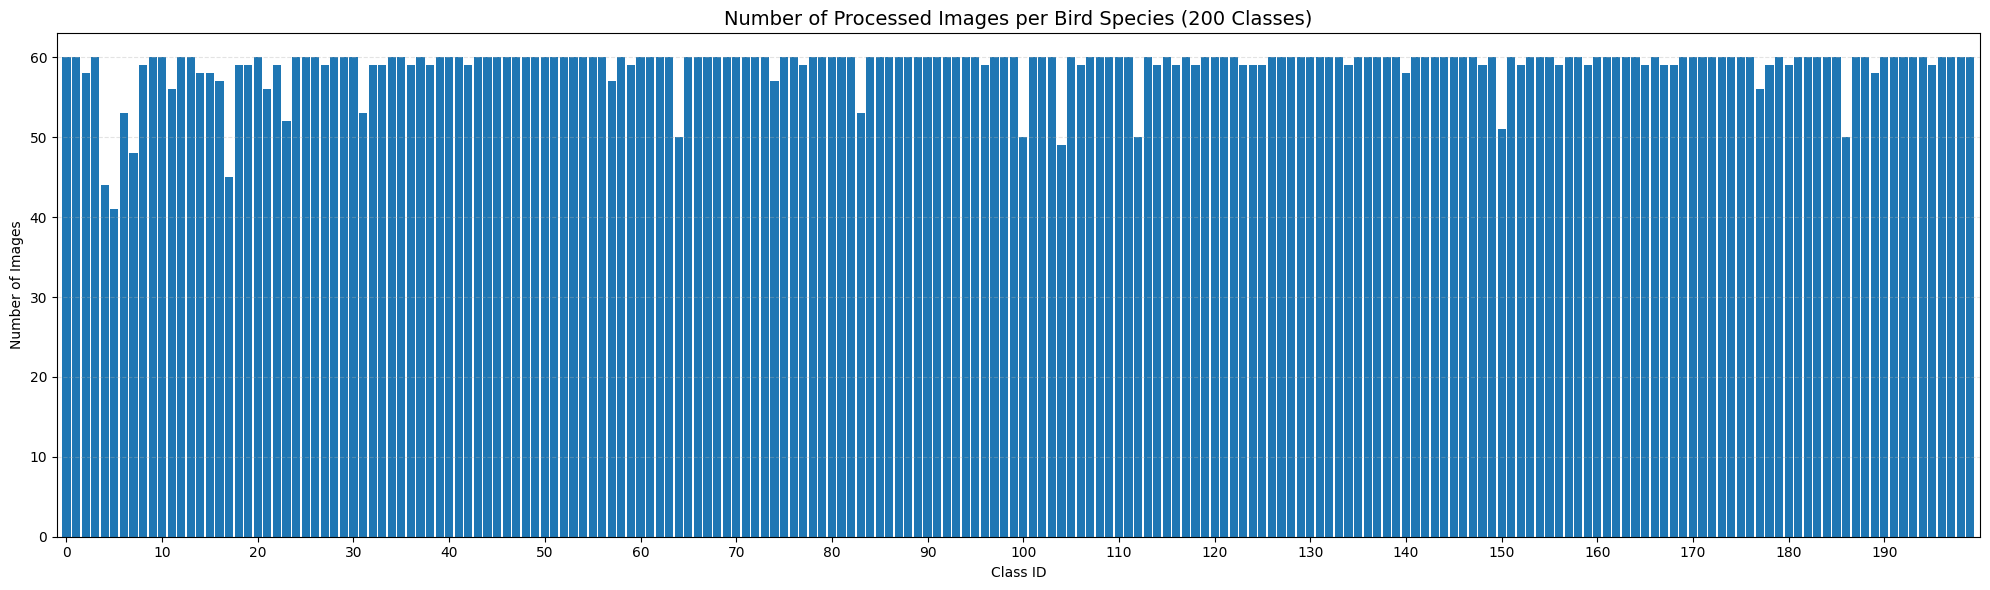

Classes represented: 200 / 200
Minimum images in a represented class: 41
Maximum images in a class: 60
Mean images per class (including zero-count classes): 58.94
Standard deviation: 2.92
Max / min ratio among represented classes: 1.46


In [4]:
class_counts = (
    metadata["label"].astype(int)
    .value_counts()
    .reindex(range(200), fill_value=0)
    .sort_index()
)

fig, ax = plt.subplots(figsize=(20, 6))
ax.bar(class_counts.index, class_counts.values, width=0.85)
ax.set_title("Number of Processed Images per Bird Species (200 Classes)", fontsize=14)
ax.set_xlabel("Class ID")
ax.set_ylabel("Number of Images")
ax.set_xlim(-1, 200)
ax.set_xticks(range(0, 200, 10))
ax.grid(axis="y", linestyle="--", alpha=0.35)
plt.tight_layout()
plt.show()

nonzero_counts = class_counts[class_counts > 0]
print(f"Classes represented: {(class_counts > 0).sum()} / 200")
print(f"Minimum images in a represented class: {nonzero_counts.min() if len(nonzero_counts) else 0}")
print(f"Maximum images in a class: {class_counts.max()}")
print(f"Mean images per class (including zero-count classes): {class_counts.mean():.2f}")
print(f"Standard deviation: {class_counts.std():.2f}")
if len(nonzero_counts):
    print(f"Max / min ratio among represented classes: {nonzero_counts.max() / nonzero_counts.min():.2f}")


## 5. Image dimensions — Are all images the same size?

We inspect the original decoded width and height stored in the processed metadata. The chart shows the most common width-height combinations, and the summary reports how many distinct resolutions occur.

If many different dimensions are present, resizing/cropping during model input preparation is useful so images can be passed to a CNN in a consistent shape. The project's transforms already handle this at runtime.


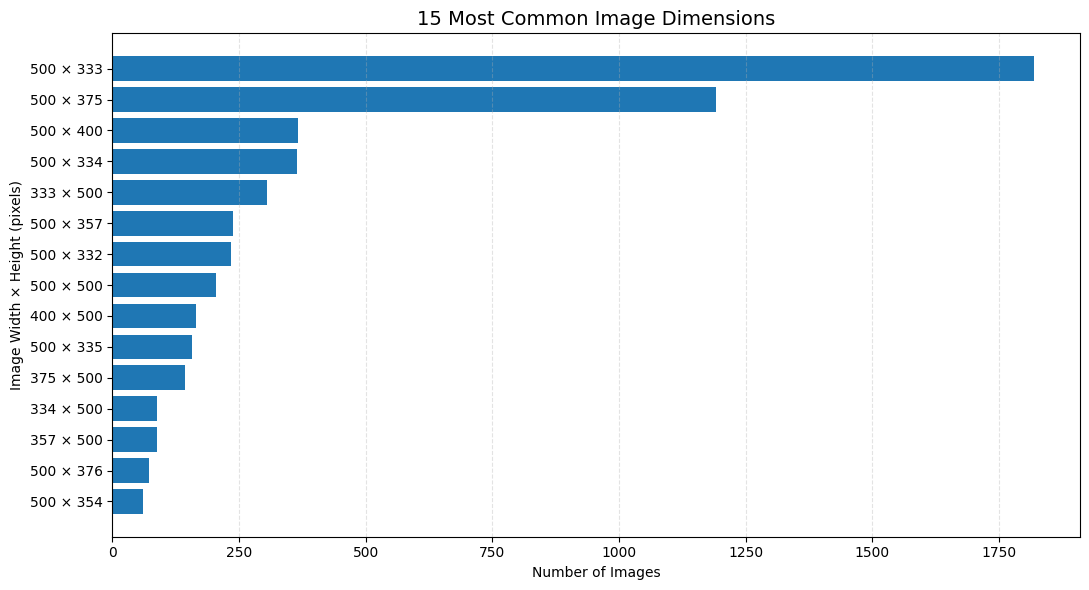

Number of unique image dimensions: 1152
Width range: 121 to 500 pixels
Height range: 120 to 500 pixels
Most common dimensions: 500 × 333 (1,819 images)
Conclusion: image dimensions vary; a consistent model input size is needed.


In [5]:
image_sizes = (
    metadata.groupby(["width", "height"])
    .size()
    .sort_values(ascending=False)
)

top_sizes = image_sizes.head(15).sort_values()
size_labels = [f"{int(width)} × {int(height)}" for width, height in top_sizes.index]

fig, ax = plt.subplots(figsize=(11, 6))
ax.barh(size_labels, top_sizes.values)
ax.set_title("15 Most Common Image Dimensions", fontsize=14)
ax.set_xlabel("Number of Images")
ax.set_ylabel("Image Width × Height (pixels)")
ax.grid(axis="x", linestyle="--", alpha=0.35)
plt.tight_layout()
plt.show()

print(f"Number of unique image dimensions: {len(image_sizes)}")
print(f"Width range: {metadata['width'].min()} to {metadata['width'].max()} pixels")
print(f"Height range: {metadata['height'].min()} to {metadata['height'].max()} pixels")
print(f"Most common dimensions: {image_sizes.index[0][0]} × {image_sizes.index[0][1]} ({image_sizes.iloc[0]:,} images)")
if len(image_sizes) == 1:
    print("Conclusion: all processed images have the same dimensions.")
else:
    print("Conclusion: image dimensions vary; a consistent model input size is needed.")


## 6. Caption length — How many words are in each description?

Each image may have multiple human-written captions. We parse the cleaned caption lists from `captions_json`, count the words in every caption, and visualize the distribution.

The mean and median help describe a typical caption length. This information is useful when choosing a reasonable maximum sequence length for the captioning decoder; the final choice should also consider how much of the caption text would be truncated.


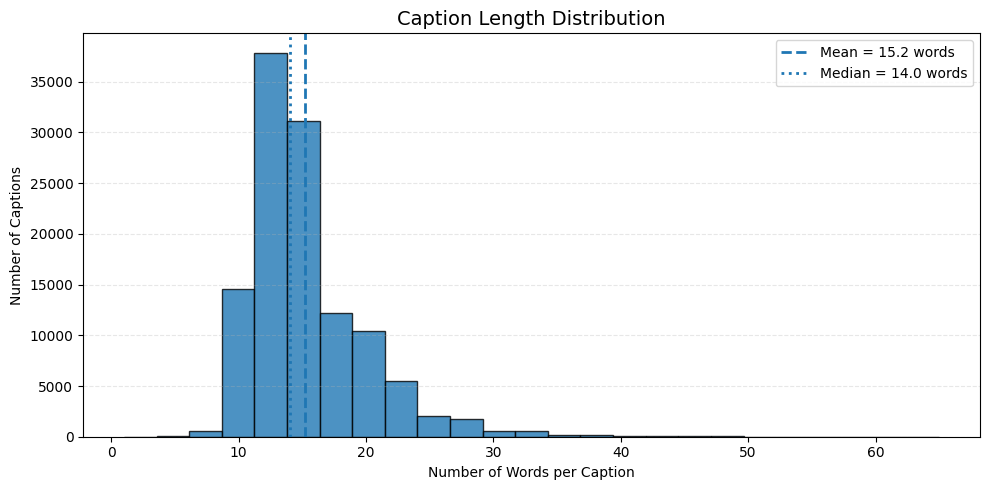

Total non-empty captions: 117,870
Mean caption length: 15.24 words
Median caption length: 14 words
Shortest caption: 1 words
Longest caption: 65 words
90th percentile: 21 words
Average captions per image: 10.00


In [6]:
def parse_caption_list(value):
    # Return a list of captions from the JSON metadata field.
    if not isinstance(value, str) or not value.strip():
        return []
    try:
        captions = json.loads(value)
    except (json.JSONDecodeError, TypeError):
        return []
    if not isinstance(captions, list):
        return []
    return [
        caption.strip()
        for caption in captions
        if isinstance(caption, str) and caption.strip()
    ]

def tokenize(text):
    return re.findall(r"\b[\w'-]+\b", text.lower())

all_captions = []
captions_per_image = []

for value in metadata["captions_json"]:
    caption_list = parse_caption_list(value)
    captions_per_image.append(len(caption_list))
    all_captions.extend(caption_list)

caption_lengths = [len(tokenize(caption)) for caption in all_captions]
caption_lengths = [length for length in caption_lengths if length > 0]

if not caption_lengths:
    raise ValueError("No non-empty captions were found in captions_json.")

length_series = pd.Series(caption_lengths)

fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(caption_lengths, bins=25, edgecolor="black", alpha=0.8)
ax.axvline(length_series.mean(), linestyle="--", linewidth=2,
           label=f"Mean = {length_series.mean():.1f} words")
ax.axvline(length_series.median(), linestyle=":", linewidth=2,
           label=f"Median = {length_series.median():.1f} words")
ax.set_title("Caption Length Distribution", fontsize=14)
ax.set_xlabel("Number of Words per Caption")
ax.set_ylabel("Number of Captions")
ax.legend()
ax.grid(axis="y", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()

print(f"Total non-empty captions: {len(caption_lengths):,}")
print(f"Mean caption length: {length_series.mean():.2f} words")
print(f"Median caption length: {length_series.median():.0f} words")
print(f"Shortest caption: {length_series.min()} words")
print(f"Longest caption: {length_series.max()} words")
print(f"90th percentile: {length_series.quantile(0.90):.0f} words")
print(f"Average captions per image: {sum(captions_per_image) / len(captions_per_image):.2f}")


## 7. Most frequent words in bird captions

We count words across all non-empty captions. To make the plot more informative, common English stopwords (such as *the*, *a*, and *with*) are excluded from the main chart. This highlights descriptive words that are more useful for understanding the caption vocabulary.

The counts are based on lowercase tokens; no spelling correction or semantic rewriting is performed.


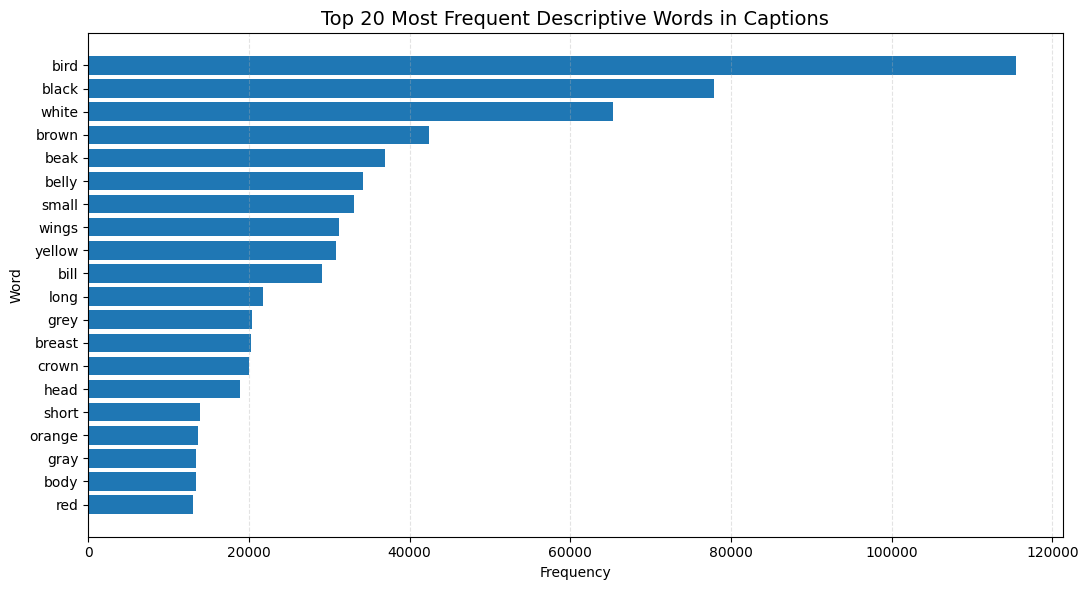

Top 20 descriptive words:


,word,frequency
0,bird,115488
1,black,77877
2,white,65279
3,brown,42374
4,beak,36925
5,belly,34229
6,small,33117
7,wings,31257
8,yellow,30807
9,bill,29084


In [7]:
stopwords = {
    "a", "an", "the", "and", "or", "but", "with", "of", "in", "on", "at",
    "to", "from", "by", "for", "is", "are", "has", "have", "this", "that",
    "it", "its", "as", "be", "been", "being", "which", "who", "while",
    "their", "they", "there", "here", "than", "into", "over", "under"
}

word_counts_all = Counter()
for caption in all_captions:
    word_counts_all.update(tokenize(caption))

descriptive_word_counts = Counter({
    word: count
    for word, count in word_counts_all.items()
    if word not in stopwords
})

top_words = descriptive_word_counts.most_common(20)
if not top_words:
    raise ValueError("No words remained after stopword filtering.")

words, counts = zip(*top_words)

fig, ax = plt.subplots(figsize=(11, 6))
ax.barh(list(words)[::-1], list(counts)[::-1])
ax.set_title("Top 20 Most Frequent Descriptive Words in Captions", fontsize=14)
ax.set_xlabel("Frequency")
ax.set_ylabel("Word")
ax.grid(axis="x", linestyle="--", alpha=0.35)
plt.tight_layout()
plt.show()

print("Top 20 descriptive words:")
display(pd.DataFrame(top_words, columns=["word", "frequency"]))


## 8. Caption coverage and dataset checks

This final check summarizes how many captions are associated with each image and highlights possible empty-caption cases in the processed metadata. It complements the caption-length analysis without changing the dataset.


In [8]:
caption_count_series = pd.Series(captions_per_image)

print("Caption count per image:")
display(
    caption_count_series.value_counts()
    .sort_index()
    .rename_axis("captions_per_image")
    .to_frame("number_of_images")
)

print(f"Images with no non-empty captions: {(caption_count_series == 0).sum():,}")
print(f"Images with exactly 10 captions: {(caption_count_series == 10).sum():,}")


Caption count per image:


,number_of_images
captions_per_image,
10,11787


Images with no non-empty captions: 0
Images with exactly 10 captions: 11,787


## 9. EDA conclusions — automatic summary

Use the actual values printed below when writing the report. The conclusions are generated from the processed metadata, so they may differ if the dataset or cleaning results change.


In [9]:
print("EDA SUMMARY")
print("=" * 60)

print(
    f"CLASS DISTRIBUTION: {int((class_counts > 0).sum())}/200 classes are represented. "
    f"Counts range from {int(nonzero_counts.min()) if len(nonzero_counts) else 0} "
    f"to {int(class_counts.max())} images among represented classes."
)
print(
    f"IMAGE DIMENSIONS: {len(image_sizes)} unique width-height combinations were found. "
    f"The most common size is {image_sizes.index[0][0]} × {image_sizes.index[0][1]} pixels."
)
print(
    f"CAPTION LENGTH: captions contain {length_series.mean():.1f} words on average "
    f"(median: {length_series.median():.0f}; 90th percentile: {length_series.quantile(0.90):.0f})."
)
print(
    f"CAPTION VOCABULARY: {len(word_counts_all):,} unique lowercase tokens were found "
    f"before stopword filtering."
)
print("MOST FREQUENT DESCRIPTIVE WORDS: " + ", ".join(word for word, _ in top_words[:10]))

print("\nInterpretation:")
print("- Check the class-distribution chart for classes with notably fewer images.")
print("- Different image dimensions support resizing/cropping to a fixed model input size.")
print("- Caption-length statistics can guide the decoder's maximum sequence length.")
print("- Frequent descriptive words give an overview of the vocabulary used by human annotators.")


EDA SUMMARY
CLASS DISTRIBUTION: 200/200 classes are represented. Counts range from 41 to 60 images among represented classes.
IMAGE DIMENSIONS: 1152 unique width-height combinations were found. The most common size is 500 × 333 pixels.
CAPTION LENGTH: captions contain 15.2 words on average (median: 14; 90th percentile: 21).
CAPTION VOCABULARY: 6,471 unique lowercase tokens were found before stopword filtering.
MOST FREQUENT DESCRIPTIVE WORDS: bird, black, white, brown, beak, belly, small, wings, yellow, bill

Interpretation:
- Check the class-distribution chart for classes with notably fewer images.
- Different image dimensions support resizing/cropping to a fixed model input size.
- Caption-length statistics can guide the decoder's maximum sequence length.
- Frequent descriptive words give an overview of the vocabulary used by human annotators.


## 10. Existing preprocessing reports for review

The preprocessing pipeline also saves detailed reports in `outputs/eda/`:

- `summary.json` — overall dataset and cleaning statistics.
- `class_distribution.csv` — image counts by original split and class label.
- `accepted_image_inventory.csv` — metadata for retained unique images.
- `excluded_items.json` — missing-label, unreadable-image and duplicate exclusions.
- `exact_duplicates.json` — exact duplicate-image details.

Review the exclusion and duplicate reports before finalizing the project report. Exact pixel duplicates are detected automatically; near-duplicates and semantic caption errors still require human review.

**Scope note:** This notebook adds visual EDA on top of the existing pipeline. It does not modify `preprocessing.py`, `transforms.py`, the train/validation/test split policy, or the image augmentation strategy.
